# Análise Exploratória de Dados (EDA) – Wine Quality

A análise exploratória de dados foi realizada com o objetivo de conhecer a estrutura, as características e o comportamento dos dados do dataset Wine Quality, identificando possíveis inconsistências, padrões e relações entre as variáveis antes da aplicação do algoritmo K-Means.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("../../data/parte_comum/winequality-red.csv", sep=";")

df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [5]:
df.shape

(1599, 12)

In [11]:
df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


A análise dos tipos de dados identificou 11 variáveis armazenadas como `float64` e uma variável armazenada como `int64`, correspondente à coluna `quality`. Todas as colunas apresentam 1599 valores não nulos. Essas informações permitem verificar como os dados estão armazenados e se há necessidade de ajustes nos tipos de dados antes das próximas etapas.

In [7]:
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

A verificação de dados ausentes não identificou valores nulos em nenhuma das variáveis do dataset. Dessa forma, não foi necessário realizar procedimentos de preenchimento ou remoção de registros em razão de dados ausentes.

In [8]:
df.duplicated().sum()

np.int64(240)

In [9]:
df[df.duplicated()]

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
4,7.4,0.700,0.00,1.90,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
11,7.5,0.500,0.36,6.10,0.071,17.0,102.0,0.99780,3.35,0.80,10.5,5
27,7.9,0.430,0.21,1.60,0.106,10.0,37.0,0.99660,3.17,0.91,9.5,5
40,7.3,0.450,0.36,5.90,0.074,12.0,87.0,0.99780,3.33,0.83,10.5,5
65,7.2,0.725,0.05,4.65,0.086,4.0,11.0,0.99620,3.41,0.39,10.9,5
...,...,...,...,...,...,...,...,...,...,...,...,...
1563,7.2,0.695,0.13,2.00,0.076,12.0,20.0,0.99546,3.29,0.54,10.1,5
1564,7.2,0.695,0.13,2.00,0.076,12.0,20.0,0.99546,3.29,0.54,10.1,5
1567,7.2,0.695,0.13,2.00,0.076,12.0,20.0,0.99546,3.29,0.54,10.1,5
1581,6.2,0.560,0.09,1.70,0.053,24.0,32.0,0.99402,3.54,0.60,11.3,5


In [34]:
quantidade_original = len(df)
quantidade_duplicatas = int(df.duplicated().sum())

resumo_duplicatas = pd.DataFrame({
    "Indicador": [
        "Registros originais",
        "Duplicatas exatas",
        "Registros únicos"
    ],
    "Quantidade": [
        quantidade_original,
        quantidade_duplicatas,
        quantidade_original - quantidade_duplicatas
    ]
})

resumo_duplicatas

,Indicador,Quantidade
0,Registros originais,1599
1,Duplicatas exatas,240
2,Registros únicos,1359


### Análise de registros duplicados

Durante a verificação da qualidade dos dados, foram identificados 240 registros duplicados entre as 1.599 observações do dataset. A presença de registros idênticos não significa necessariamente que existam erros, pois diferentes amostras de vinho podem apresentar os mesmos valores para as características físico-químicas analisadas. Optou-se por manter os registros duplicados, considerando que não há evidências suficientes para classificá-los como erros. A remoção dessas observações poderia modificar a distribuição original dos dados e influenciar os resultados do agrupamento pelo K-Means, uma vez que registros repetidos possuem maior peso na formação dos clusters.

In [10]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


As estatísticas descritivas permitem observar aspectos gerais da distribuição das variáveis numéricas, incluindo medidas de tendência central, dispersão e valores extremos. Essas informações contribuem para compreender as características do dataset e auxiliam na identificação de possíveis diferenças de escala entre as variáveis, aspecto relevante para a aplicação do K-Means.

### Análise distributiva

A análise distributiva foi realizada por meio de gráficos de contagem e histogramas, com o objetivo de observar a frequência dos valores, a concentração dos dados e o comportamento das distribuições de cada variável. Essa etapa permite compreender melhor as características do dataset e identificar possíveis padrões e assimetrias.

In [11]:
df["quality"].value_counts().sort_index()

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

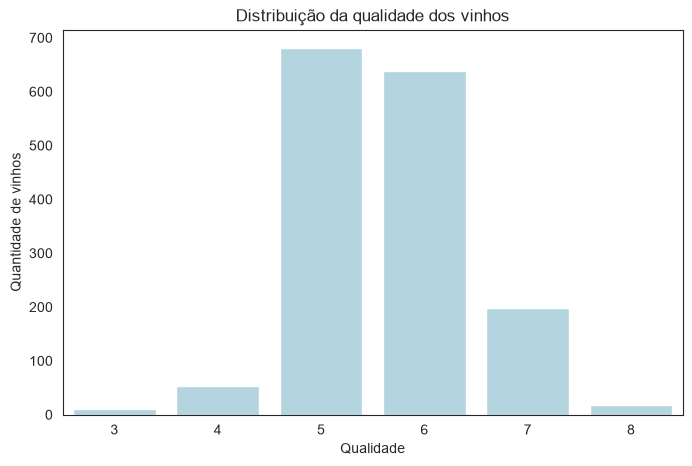

In [21]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="quality", color="lightblue")

plt.title("Distribuição da qualidade dos vinhos")
plt.xlabel("Qualidade")
plt.ylabel("Quantidade de vinhos")
plt.grid(False)

plt.show()

A distribuição da variável `quality` indica uma maior concentração de vinhos classificados com notas 5 e 6, sendo a nota 5 a mais frequente. Em contrapartida, as notas 3 e 8 apresentam uma quantidade significativamente menor de registros. Dessa forma, observa-se que as classes de qualidade estão distribuídas de maneira desigual no dataset.

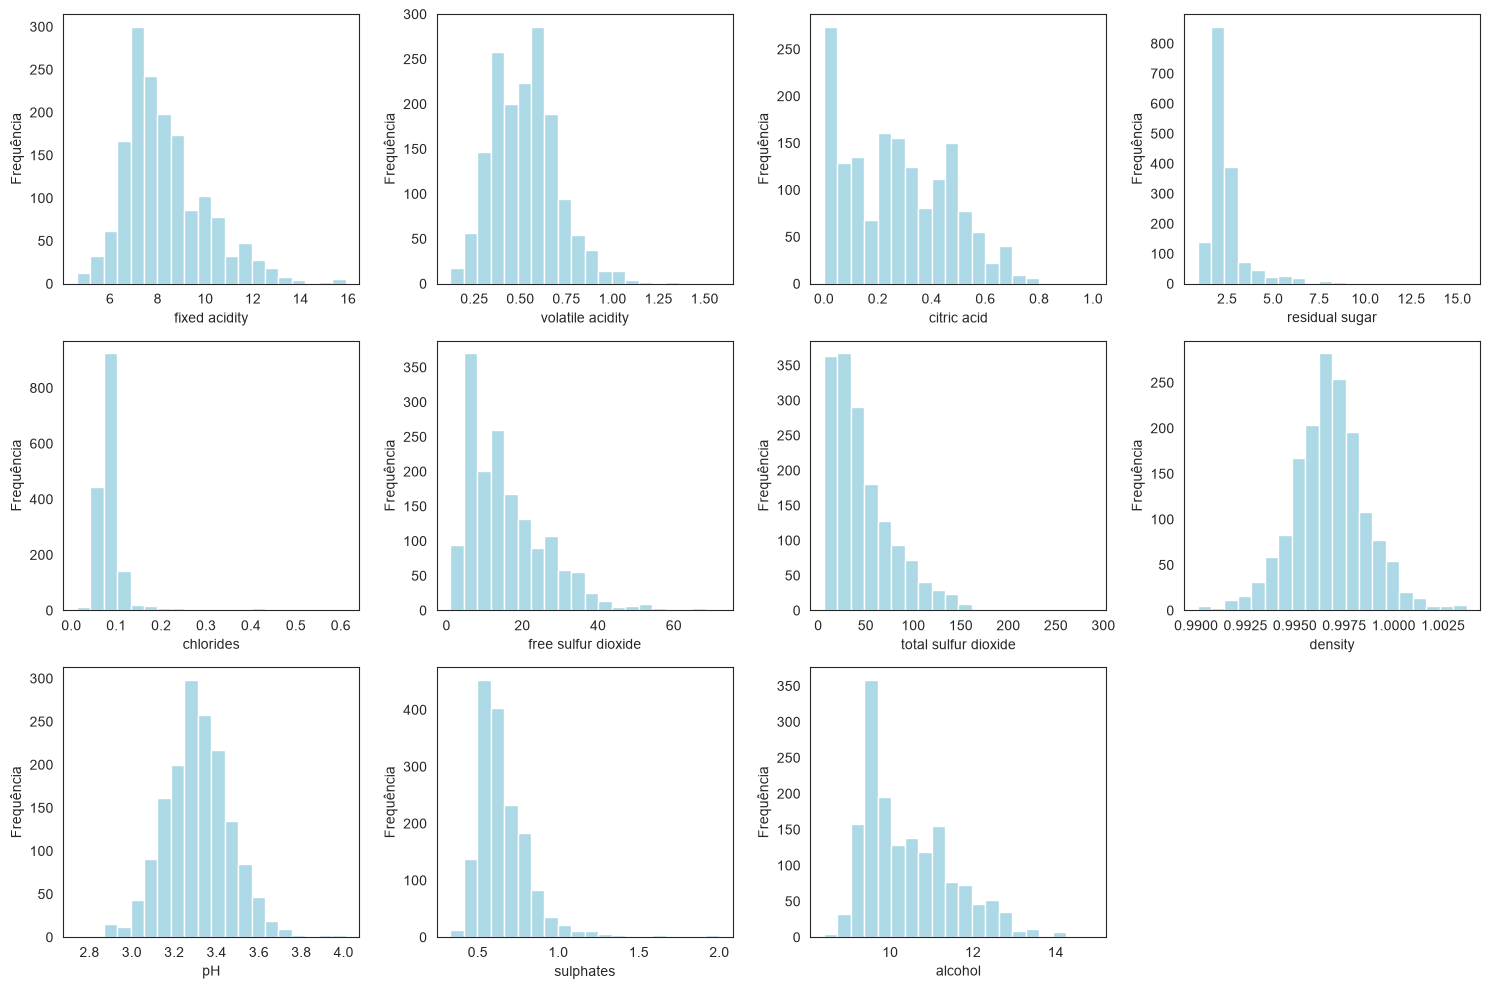

In [20]:
colunas = df.drop(columns="quality").columns

fig, axes = plt.subplots(3, 4, figsize=(15, 10))

for ax, coluna in zip(axes.flatten(), colunas):
    ax.hist(df[coluna], bins=20, color="lightblue")
    ax.set_xlabel(coluna)
    ax.set_ylabel("Frequência")
    ax.grid(False)

axes.flatten()[-1].set_visible(False)

plt.tight_layout()
plt.show()

A análise dos histogramas revelou que algumas variáveis apresentam distribuições assimétricas, com maior concentração de valores em faixas menores e uma cauda à direita, como observado em `residual sugar`, `chlorides`, `free sulfur dioxide`, `total sulfur dioxide` e `sulphates`. Outras variáveis, como `density` e `pH`, apresentam distribuições mais concentradas e relativamente simétricas. Essas diferenças demonstram que as variáveis possuem comportamentos e distribuições distintas.

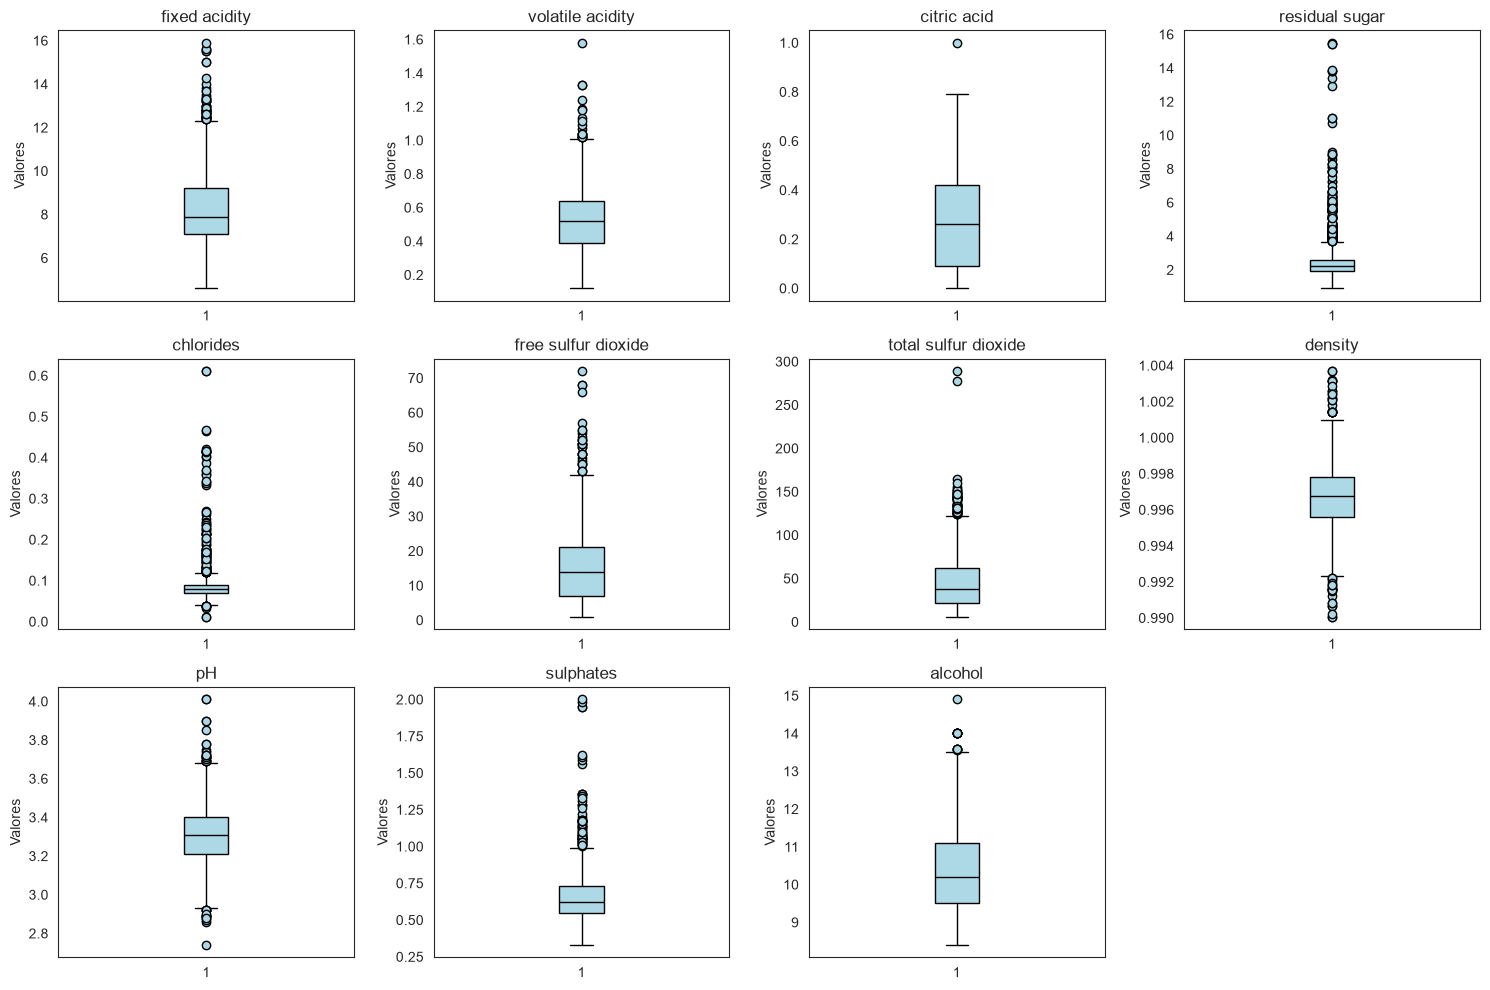

In [19]:
colunas = df.drop(columns="quality").columns

fig, axes = plt.subplots(3, 4, figsize=(15, 10))

for ax, coluna in zip(axes.flatten(), colunas):
    ax.boxplot(
        df[coluna],
        patch_artist=True,
        boxprops=dict(facecolor="lightblue"),
        medianprops=dict(color="black"),
        whiskerprops=dict(color="black"),
        capprops=dict(color="black"),
        flierprops=dict(markerfacecolor="lightblue", markeredgecolor="black")
    )
    ax.set_title(coluna)
    ax.set_ylabel("Valores")
    ax.grid(False)

axes.flatten()[-1].set_visible(False)

plt.tight_layout()
plt.show()

Os boxplots permitiram visualizar a presença de possíveis outliers em diferentes variáveis do dataset. Observou-se que algumas apresentam pontos mais distantes da concentração principal dos dados, especialmente `residual sugar`, `chlorides` e `sulphates`. Também foram identificados possíveis outliers em outras variáveis. 

In [22]:
colunas = df.drop(columns="quality").columns

outliers = {}

for coluna in colunas:
    q1 = df[coluna].quantile(0.25)
    q3 = df[coluna].quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    quantidade = ((df[coluna] < limite_inferior) | (df[coluna] > limite_superior)).sum()

    outliers[coluna] = quantidade

pd.Series(outliers, name="Quantidade de possíveis outliers")

fixed acidity            49
volatile acidity         19
citric acid               1
residual sugar          155
chlorides               112
free sulfur dioxide      30
total sulfur dioxide     55
density                  45
pH                       35
sulphates                59
alcohol                  13
Name: Quantidade de possíveis outliers, dtype: int64

In [23]:
resultado_outliers = pd.DataFrame(outliers.items(), columns=["Variável", "Quantidade"])

resultado_outliers["Porcentagem"] = (resultado_outliers["Quantidade"] / len(df)) * 100

resultado_outliers

,Variável,Quantidade,Porcentagem
0,fixed acidity,49,3.064415
1,volatile acidity,19,1.188243
2,citric acid,1,0.062539
3,residual sugar,155,9.693558
4,chlorides,112,7.004378
5,free sulfur dioxide,30,1.876173
6,total sulfur dioxide,55,3.439650
7,density,45,2.814259
8,pH,35,2.188868
9,sulphates,59,3.689806


A quantificação dos possíveis outliers pelo método IQR evidenciou diferenças entre as variáveis analisadas. As variáveis `residual sugar` e `chlorides` apresentaram as maiores quantidades de possíveis outliers, com 155 e 112 registros, respectivamente. Outras variáveis, como `sulphates`, `total sulfur dioxide` e `fixed acidity`, também apresentaram valores identificados pelo método. Esses resultados indicam a presença de observações mais distantes da distribuição central em determinadas características físico-químicas do dataset.

### Tratamento dos outliers

Optou-se por manter os possíveis outliers identificados pelo método IQR, sem realizar sua remoção ou substituição. Essa decisão considera que valores estatisticamente atípicos não representam necessariamente erros nos dados. Entretanto, sua presença pode influenciar os resultados do K-Means, já que o algoritmo utiliza distâncias para formar os agrupamentos e é sensível a valores extremos.

### Análise relacional

Nesta etapa, foram exploradas as relações entre as variáveis numéricas do dataset por meio da matriz de correlação e de gráficos de dispersão. A matriz permitiu visualizar as correlações entre as variáveis, enquanto os gráficos de dispersão foram utilizados para observar individualmente algumas dessas relações.

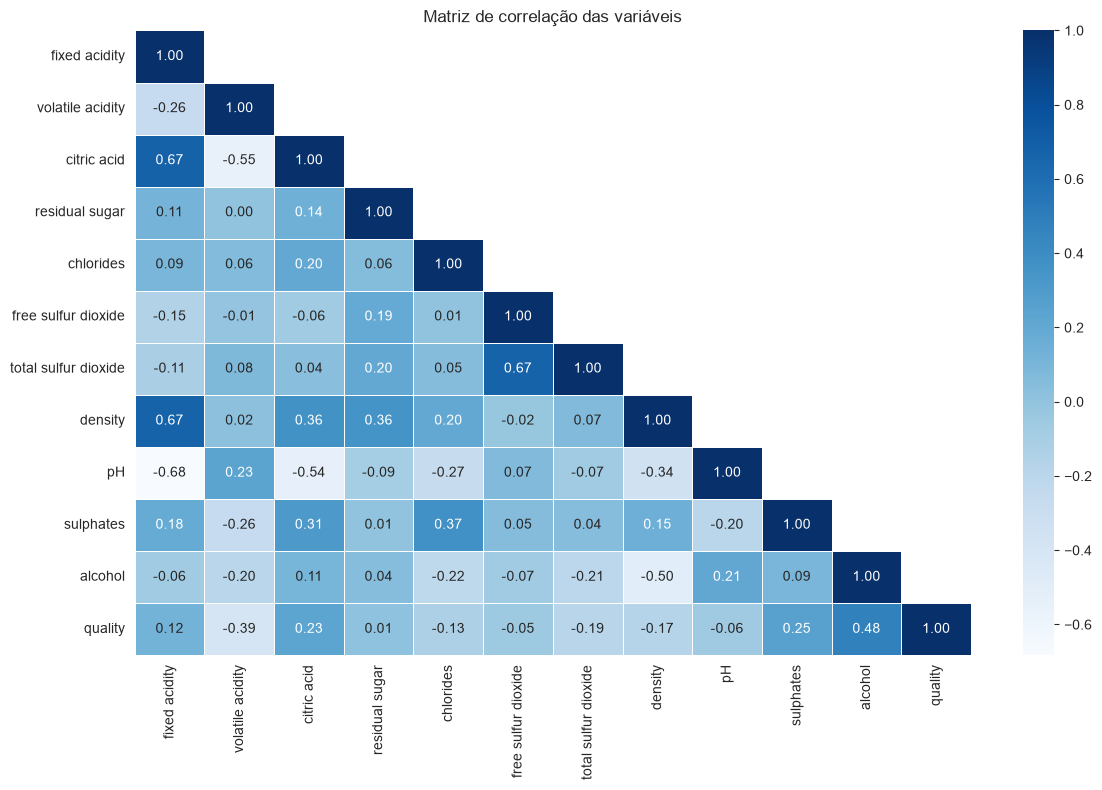

In [25]:
correlacao = df.corr()

mascara = np.triu(np.ones_like(correlacao, dtype=bool), k=1)

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlacao,
    mask=mascara,
    annot=True,
    cmap="Blues",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Matriz de correlação das variáveis")
plt.grid(False)

plt.tight_layout()
plt.show()

A matriz de correlação permitiu observar diferentes níveis de associação linear entre as variáveis. Em relação à variável `quality`, destacam-se `alcohol`, com correlação positiva, e `volatile acidity`, com correlação negativa, indicando que essas variáveis apresentam associações lineares mais evidentes com a qualidade dos vinhos dentro do dataset. Entretanto, essas correlações não implicam necessariamente uma relação de causalidade.

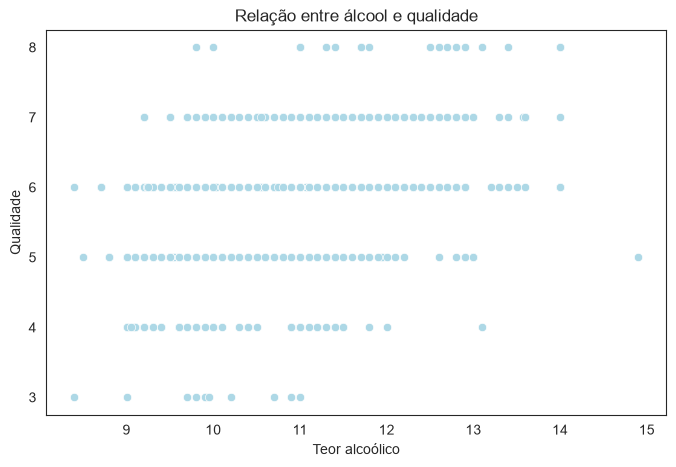

In [26]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="alcohol", y="quality", color="lightblue")

plt.title("Relação entre álcool e qualidade")
plt.xlabel("Teor alcoólico")
plt.ylabel("Qualidade")
plt.grid(False)

plt.show()

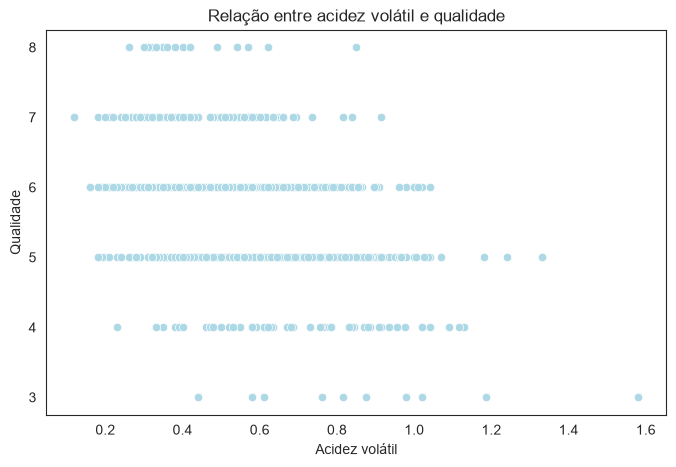

In [27]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="volatile acidity", y="quality", color="lightblue")

plt.title("Relação entre acidez volátil e qualidade")
plt.xlabel("Acidez volátil")
plt.ylabel("Qualidade")
plt.grid(False)

plt.show()

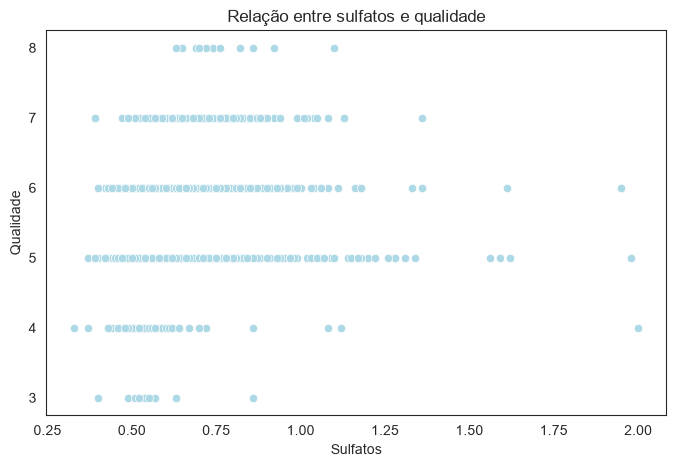

In [28]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="sulphates", y="quality", color="lightblue")

plt.title("Relação entre sulfatos e qualidade")
plt.xlabel("Sulfatos")
plt.ylabel("Qualidade")
plt.grid(False)

plt.show()

Os gráficos de dispersão complementam a análise da matriz de correlação, permitindo observar as associações entre algumas características físico-químicas e a qualidade dos vinhos. A variável `alcohol` apresenta uma tendência positiva em relação à `quality`, enquanto `volatile acidity` apresenta uma tendência negativa. Já `sulphates` demonstra uma associação positiva menos evidente. Essas observações reforçam os resultados identificados na matriz de correlação, embora não indiquem relações de causalidade.

## Preparação dos dados para aplicação do K-Means

Nesta etapa, serão realizadas as verificações e os procedimentos necessários para preparar os dados para a aplicação do algoritmo K-Means, considerando aspectos como duplicatas, possíveis outliers e escalas das variáveis.